# A4_1 · NumPy 문서 검색과 분류

**단일 실행 노트북 · 구현 → 검증 → 한계 분석 → 구술 대비 → 별도 보너스**

이 파일 안에 전처리·TF-IDF·코사인 검색·분류·보너스 구현과 설명을 모두 포함했습니다.
저장소의 `src`, 불용어 파일, 기존 측정 JSON·이미지를 읽지 않습니다.
패키지를 준비한 다음 **Python 커널 선택 → Restart Kernel → Run All**로 실행합니다.
실행 결과는 이 노트북 출력에 저장되며 혼동 행렬도 내장됩니다.

## 실행 준비

검증 환경은 **Python 3.14.7**입니다. 미션 최소 조건은 Python 3.10+이며 아래 고정 패키지는 3.14.7에서 검증했습니다.
노트북 파일만 새 폴더로 복사해 사용할 때는 해당 환경의 터미널에서 다음 명령을 실행합니다.

```bash
python -m pip install numpy==2.5.4 scikit-learn==1.9.1 scipy==1.18.1 matplotlib==3.11.2 threadpoolctl==3.8.0 ipykernel==7.4.0 jupyterlab==4.6.6
python -m jupyterlab A4_1_mission.ipynb
```

저장소에서는 `uv pip install -r requirements-notebook.txt` 후 VS Code에서 `.venv` 커널을 선택해도 됩니다.
의존성은 최초 한 번 설치합니다. 데이터는 sklearn으로 최초 다운로드하며 이후 `artifacts/data_cache`를 사용합니다.
기존 캐시를 쓰려면 커널을 시작하기 전에 환경변수 `A4_1_DATA_HOME`으로 캐시 폴더를 지정합니다.
실행 중 생성하는 인덱스·지표·그림은 현재 폴더의 `artifacts/notebook`에 저장합니다.
Dense Train TF-IDF만 약 770 MiB이므로 여유 메모리를 확보하고 큰 실험 행렬은 순차 처리합니다.

## 출처와 검수 범위

20 Newsgroups 네 범주의 문서를 사용합니다. 배포 기록: **Nelson Liu (2016), scikit-learn 20newsgroups dataset 20news-bydate.tar.gz, v2, Figshare**.
[DOI: 10.6084/m9.figshare.3829962.v2](https://doi.org/10.6084/m9.figshare.3829962.v2),
파일 ID `5975967`, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
범주 선택·헤더/푸터/인용 제거·이메일/일반 전화번호 마스킹·빈 문서 제외·8:2 재분할·수치 변환을 적용합니다.
고정 불용어 123개는 제공 소스의 프로젝트 기준 `a4-1-en-v1`이며 외부 원출처·버전은 제공되지 않았습니다.

**데이터 검수 상태:** 전체 코퍼스 인명·서명 수동 검수는 [이슈 #8](https://github.com/ntt65/A4_1/issues/8)에 남아 있습니다.
미션의 개인정보 미포함 조건은 이 검수가 끝난 뒤 완료 판정할 수 있습니다.
이 노트북은 공개 출력에 원문·잔존 서명·전체 어휘를 덤프하지 않고 수치·레이블·문서 ID·feature ID를 표시합니다.
`search()`는 미션 규격대로 스니펫을 반환하되 출력 예제에서는 해당 필드를 표시하지 않습니다.
오분류 설명에는 사전에 검토한 짧은 비식별 근거를 사용합니다.

## 평가 항목과 노트북의 대응

미션 PDF 7쪽, 평가 PDF 11쪽을 직접 대조했습니다. `1-1` 등은 평가표 항목 안의 **질문 순서**를 표시한 번호입니다.

| 평가표 | 이 노트북의 근거 |
| --- | --- |
| 1-1, 2-2, 3-1, 3-3 | M2 NumPy TF→DF→IDF→TF-IDF, sklearn 대조·shape·오차 assertion |
| 1-2, 1-6, 3-2 | M3 코사인·Top-5·함수 API·인덱스 저장/재로딩 |
| 1-3, 1-5 | M4 Accuracy·Macro-F1·혼동 행렬·실제 오류 5건 |
| 1-4, 2-1, 2-3 | M1 공통 전처리·학습/시험 분리, Q1·Q5 설계 설명 |
| 4-1~4-4 | BoW 한계·다의어·대규모 병목·후속 품질 평가 |
| 5 | 맨 아래 별도 보너스: TF 변형·BM25·역색인 |

README 3단 구성과 `requirements.txt`는 저장소 제출 문서로 함께 유지합니다.
실행 수치는 저장된 과거 보고값을 읽지 않고 아래 셀에서 다시 계산합니다.


## 1. 구현 요약 — 환경과 재현 조건

이 노트북은 핵심 구현을 셀 안에 정의합니다. 처음부터 순서대로 실행하면 고정된 Train/Test 분할로 전처리·검색·분류·검증을 재계산합니다. 첫 데이터 다운로드 이후에는 로컬 캐시를 재사용합니다. `src`, 외부 불용어 파일, 기존 측정 JSON·그림은 읽지 않습니다.

- 데이터: 20 Newsgroups의 네 범주. 배포자는 Nelson Liu(2016), Figshare DOI [10.6084/m9.figshare.3829962.v2](https://doi.org/10.6084/m9.figshare.3829962.v2), 파일 5975967에 CC BY 4.0이 표시됩니다.
- 메일 헤더·푸터·인용문을 제거하고 이메일·일반 전화번호를 마스킹합니다. 전체 코퍼스의 인명·서명 수동 검수는 [이슈 #8](https://github.com/ntt65/A4_1/issues/8)에 남아 있습니다.
- 공개 출력은 집계·클래스·문서 ID와 작성한 예문 중심입니다. 함수는 미션의 150자 스니펫을 반환하지만 실제 코퍼스 스니펫을 출력에 저장하지 않습니다.
- 기본 캐시는 현재 폴더의 `artifacts/data_cache`입니다. `A4_1_DATA_HOME` 환경변수로 기존 데이터 캐시를 지정할 수 있습니다. 인덱스 등 로컬 생성 파일은 `artifacts/notebook`에 저장합니다.

In [1]:
import gc
import hashlib
import json
import os
import platform
import re
import sys
from numbers import Integral
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sklearn
from IPython.display import display
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split

get_ipython().run_line_magic("matplotlib", "inline")
DATA_HOME = Path(os.environ.get("A4_1_DATA_HOME", Path.cwd() / "artifacts" / "data_cache")).resolve()
OUTPUT_DIR = Path.cwd() / "artifacts" / "notebook"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
environment = {
    "python": platform.python_version(), "numpy": np.__version__,
    "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__, "seed": SEED,
}
print(json.dumps(environment, indent=2))


{
  "python": "3.14.7",
  "numpy": "2.5.4",
  "scikit-learn": "1.9.1",
  "scipy": "1.18.1",
  "matplotlib": "3.11.2",
  "seed": 42
}


### M1. 전처리 규칙과 데이터 분할

소문자화 후 정규식 `r'(?u)\b\w\w+\b'`로 두 글자 이상의 Unicode 단어를 뽑고 고정 불용어 123개를 제외합니다. 숫자·밑줄도 단어 문자이며 한 글자 `C`나 `C++`의 정보는 손실됩니다. 이 목록은 제공 소스의 프로젝트 정책 `a4-1-en-v1`입니다. 외부 목록의 원출처·버전은 제공되지 않았습니다. 부정어 `no/nor/not` 제거의 한계도 뒤에서 다룹니다.

헤더·푸터·인용문 제거 → 마스킹 → 빈 본문 제외 → 층화 8:2 분할 순서입니다. 어휘와 IDF는 Train에서만 학습합니다.

In [2]:
STOPWORDS_TEXT = """a
about
above
after
again
against
all
am
an
and
any
are
as
at
be
because
been
before
being
below
between
both
but
by
can
did
do
does
doing
down
during
each
few
for
from
further
had
has
have
having
he
her
here
hers
herself
him
himself
his
how
i
if
in
into
is
it
its
itself
just
me
more
most
my
myself
no
nor
not
now
of
off
on
once
only
or
other
our
ours
ourselves
out
over
own
same
she
should
so
some
such
than
that
the
their
theirs
them
themselves
then
there
these
they
this
those
through
to
too
under
until
up
very
was
we
were
what
when
where
which
while
who
whom
why
with
you
your
yours
yourself
yourselves"""
STOPWORDS = set(STOPWORDS_TEXT.split())
STOPWORDS_SHA256 = hashlib.sha256((STOPWORDS_TEXT.rstrip() + "\n").encode("utf-8")).hexdigest()
assert len(STOPWORDS) == 123
assert STOPWORDS_SHA256 == "566c5909c1523a651dc2691ff0fa4fddabcc2d047daceccd2f4b962789af313d"

class TextPreprocessor:
    def __init__(self, stopwords=None):
        self.stopwords = set(STOPWORDS if stopwords is None else stopwords)
        self.token_pattern = re.compile(r"(?u)\b\w\w+\b")

    def tokenize(self, text):
        return [
            token for token in self.token_pattern.findall(text.lower())
            if token not in self.stopwords
        ]

EMAIL_PATTERN = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")
PHONE_PATTERN = re.compile(
    r"(?<!\w)(?:\+?\d{1,3}[- .]?)?(?:\(?\d{2,4}\)?[- .]?)?\d{3}[- .]?\d{4}(?!\w)"
)

def clean_text(text):
    return PHONE_PATTERN.sub("[PHONE]", EMAIL_PATTERN.sub("[EMAIL]", text))

preprocessor = TextPreprocessor()
assert preprocessor.tokenize("The GRAPHICS system and orbit.") == ["graphics", "system", "orbit"]
assert preprocessor.tokenize("the and") == []
assert preprocessor.tokenize("C C++") == []
print("Preprocessing checks PASS; stopwords:", len(STOPWORDS))


Preprocessing checks PASS; stopwords: 123


In [3]:
CATEGORIES = [
    "comp.graphics", "rec.sport.baseball", "sci.space", "talk.politics.mideast"
]
raw_data = fetch_20newsgroups(
    subset="all", categories=CATEGORIES, remove=("headers", "footers", "quotes"),
    random_state=SEED, data_home=str(DATA_HOME),
)
cleaned_docs = [clean_text(doc) for doc in raw_data.data]
retained = [i for i, doc in enumerate(cleaned_docs) if doc.strip()]
documents = [cleaned_docs[i] for i in retained]
labels = np.asarray(raw_data.target)[retained]
target_names = list(raw_data.target_names)
train_docs, test_docs, y_train, y_test = train_test_split(
    documents, labels, test_size=0.2, random_state=SEED, stratify=labels
)
corpus_stats = {
    "raw_documents": len(cleaned_docs), "documents": len(documents),
    "removed_empty": len(cleaned_docs) - len(documents),
    "train_documents": len(train_docs), "test_documents": len(test_docs),
    "train_counts": np.bincount(y_train).tolist(),
    "test_counts": np.bincount(y_test).tolist(),
    "target_names": target_names,
    "identical_train_test_bodies": len(set(train_docs) & set(test_docs)),
    "remaining_email_patterns": sum(len(EMAIL_PATTERN.findall(d)) for d in documents),
    "remaining_phone_patterns": sum(len(PHONE_PATTERN.findall(d)) for d in documents),
    "corpus_sha256": hashlib.sha256("\0".join(documents).encode("utf-8")).hexdigest(),
    "stopwords_sha256": STOPWORDS_SHA256,
}
assert corpus_stats["identical_train_test_bodies"] == 0
assert corpus_stats["remaining_email_patterns"] == 0
assert corpus_stats["remaining_phone_patterns"] == 0
assert set(np.unique(y_train)) == set(np.unique(y_test)) == set(range(4))
print(json.dumps(corpus_stats, indent=2))
del raw_data, cleaned_docs, retained


{
  "raw_documents": 3894,
  "documents": 3787,
  "removed_empty": 107,
  "train_documents": 3029,
  "test_documents": 758,
  "train_counts": [
    764,
    766,
    764,
    735
  ],
  "test_counts": [
    191,
    192,
    191,
    184
  ],
  "target_names": [
    "comp.graphics",
    "rec.sport.baseball",
    "sci.space",
    "talk.politics.mideast"
  ],
  "identical_train_test_bodies": 0,
  "remaining_email_patterns": 0,
  "remaining_phone_patterns": 0,
  "corpus_sha256": "56c82569138106bb0cc167ec4c880d1beb41645758f4dffd9acbf60f78ad21de",
  "stopwords_sha256": "566c5909c1523a651dc2691ff0fa4fddabcc2d047daceccd2f4b962789af313d"
}


### M2. NumPy TF-IDF와 코사인 유사도

문서 수를 $N$, 단어 출현 횟수를 $c_{d,t}$라 하면 다음과 같습니다.

$$tf(d,t)=c_{d,t},\quad df(t)=\sum_d \mathbf{1}[c_{d,t}>0]$$
$$idf(t)=\ln\frac{1+N}{1+df(t)}+1,\quad x_{d,t}=tf(d,t)\,idf(t)$$
$$\hat x_d=\frac{x_d}{\|x_d\|_2}\;(\|x_d\|_2>0),\qquad
\cos(d,q)=\hat d\cdot\hat q$$

영벡터는 0으로 유지합니다. 정렬된 어휘 열과 `float64`를 사용하고 Test/OOV는 학습된 어휘·IDF만 적용합니다. sklearn은 이 구현의 검증 참조입니다.

In [4]:
class CustomTfidfVectorizer:
    """NumPy count TF, smooth IDF and zero-safe L2 normalization."""
    def __init__(self, preprocessor=None):
        self.preprocessor = preprocessor if preprocessor is not None else TextPreprocessor()
        self.vocabulary_ = {}
        self.idf_ = np.array([], dtype=np.float64)
        self.df_ = np.array([], dtype=np.float64)
        self.n_features_in_ = 0

    def fit(self, raw_documents):
        docs = list(raw_documents)
        tokens = [self.preprocessor.tokenize(doc) for doc in docs]
        terms = sorted({term for doc in tokens for term in doc})
        if not terms:
            raise ValueError("Cannot fit an empty vocabulary")
        self.vocabulary_ = {term: i for i, term in enumerate(terms)}
        self.n_features_in_ = len(terms)
        self.df_ = np.zeros(len(terms), dtype=np.float64)
        for doc in tokens:
            for term in set(doc):
                self.df_[self.vocabulary_[term]] += 1
        self.idf_ = np.log((1.0 + len(docs)) / (1.0 + self.df_)) + 1.0
        return self

    def count_matrix(self, raw_documents):
        if not self.vocabulary_:
            raise ValueError("Fit before transform")
        docs = list(raw_documents)
        counts = np.zeros((len(docs), self.n_features_in_), dtype=np.float64)
        for row, doc in enumerate(docs):
            for token in self.preprocessor.tokenize(doc):
                column = self.vocabulary_.get(token)
                if column is not None:
                    counts[row, column] += 1.0
        return counts

    def transform(self, raw_documents):
        weighted = self.count_matrix(raw_documents)
        weighted *= self.idf_
        norms = np.linalg.norm(weighted, axis=1, keepdims=True)
        np.divide(weighted, norms, out=weighted, where=norms != 0)
        return weighted

    def fit_transform(self, raw_documents):
        docs = list(raw_documents)
        return self.fit(docs).transform(docs)

# 직접 작성한 작은 코퍼스로 TF/DF/IDF를 수작업 대조합니다.
toy_vectorizer = CustomTfidfVectorizer(TextPreprocessor(stopwords=set())).fit(
    ["red red blue", "blue green", ""]
)
np.testing.assert_array_equal(
    toy_vectorizer.count_matrix(["red red blue", "blue green", ""]),
    [[1, 0, 2], [1, 1, 0], [0, 0, 0]],
)  # 열: blue, green, red
np.testing.assert_array_equal(toy_vectorizer.df_, [2, 1, 1])
np.testing.assert_allclose(toy_vectorizer.idf_, np.log(4 / np.array([3, 2, 2])) + 1)
assert np.all(toy_vectorizer.transform(["", "unknownword"]) == 0)
print("Manual TF/DF/IDF and zero-vector checks PASS")


Manual TF/DF/IDF and zero-vector checks PASS


## 2. 검증 및 실험 결과

### 단계별 sklearn 대조

같은 analyzer, smooth IDF, Raw TF, L2 정규화, `float64` 조건으로 비교합니다. 어휘·열 순서·TF·DF·IDF를 먼저 검증하고 Train/Test/빈 질의/불용어 질의/OOV의 최종 벡터를 대조합니다. 큰 참조 dense 행렬을 중복 저장하지 않도록 128문서씩 계산합니다. 최대 절대 오차가 $10^{-6}$ 이상이면 즉시 실패합니다.

In [5]:
vectorizer = CustomTfidfVectorizer(preprocessor).fit(train_docs)
reference = TfidfVectorizer(
    analyzer=preprocessor.tokenize, smooth_idf=True,
    norm="l2", sublinear_tf=False, dtype=np.float64,
).fit(train_docs)
assert vectorizer.vocabulary_ == reference.vocabulary_, "Vocabulary/column mismatch"
counter = CountVectorizer(analyzer=preprocessor.tokenize, vocabulary=reference.vocabulary_)
reference_counts = counter.transform(train_docs)
reference_df = np.asarray((reference_counts > 0).sum(axis=0)).ravel()
np.testing.assert_array_equal(vectorizer.df_, reference_df)
np.testing.assert_allclose(vectorizer.idf_, reference.idf_, rtol=0, atol=1e-12)
idf_error = float(np.max(np.abs(vectorizer.idf_ - reference.idf_)))
validation_groups = {
    "train": train_docs, "test": test_docs,
    "queries": ["space satellite launch orbit", "graphics rendering", "", "the and", "zzzzzzunseenword"],
}
verify_results = {
    "status": "PASS", "threshold": 1e-6, "idf_max_error": idf_error,
    "vocabulary_size": len(vectorizer.vocabulary_), "groups": {},
}
for name, docs in validation_groups.items():
    maximum, error_sum, count = 0.0, 0.0, 0
    for start in range(0, len(docs), 128):
        batch = docs[start:start + 128]
        counts = vectorizer.count_matrix(batch)
        np.testing.assert_array_equal(counts, counter.transform(batch).toarray())
        del counts
        actual = vectorizer.transform(batch)
        expected = reference.transform(batch).toarray()
        assert actual.shape == expected.shape
        errors = np.abs(actual - expected)
        maximum = max(maximum, float(errors.max(initial=0)))
        error_sum += float(errors.sum())
        count += errors.size
        del actual, expected, errors
    assert maximum < verify_results["threshold"], f"{name}: error threshold exceeded"
    verify_results["groups"][name] = {
        "shape": [len(docs), len(vectorizer.vocabulary_)],
        "max_absolute_error": maximum,
        "mean_absolute_error": error_sum / max(count, 1),
    }
    print(f"{name}: max={maximum:.4e}, mean={error_sum / max(count, 1):.4e}")
assert np.all(vectorizer.transform(["", "the and", "zzzzzzunseenword"]) == 0)
# 어휘·IDF가 transform 과정에서 변하지 않았음을 확인합니다.
assert vectorizer.vocabulary_ == reference.vocabulary_
np.testing.assert_array_equal(vectorizer.idf_, reference.idf_)
del reference_counts, reference_df, counter, reference
gc.collect()
X_train = vectorizer.transform(train_docs)
X_test = vectorizer.transform(test_docs)
train_norms = np.linalg.norm(X_train, axis=1)
np.testing.assert_allclose(train_norms[train_norms > 0], 1.0, atol=1e-12)
print(json.dumps(verify_results, indent=2))


train: max=2.3315e-15, mean=3.0568e-20


test: max=8.3267e-16, mean=2.2134e-20
queries: max=0.0000e+00, mean=0.0000e+00


{
  "status": "PASS",
  "threshold": 1e-06,
  "idf_max_error": 0.0,
  "vocabulary_size": 33297,
  "groups": {
    "train": {
      "shape": [
        3029,
        33297
      ],
      "max_absolute_error": 2.3314683517128287e-15,
      "mean_absolute_error": 3.056800952156508e-20
    },
    "test": {
      "shape": [
        758,
        33297
      ],
      "max_absolute_error": 8.326672684688674e-16,
      "mean_absolute_error": 2.2134100874712442e-20
    },
    "queries": {
      "shape": [
        5,
        33297
      ],
      "max_absolute_error": 0.0,
      "mean_absolute_error": 0.0
    }
  }
}


### M3. 코사인 검색·함수 API·인덱스 재로딩

정규화된 문서 행렬과 질의 벡터의 내적으로 코사인 점수를 계산합니다. 양수 점수만 반환하고 **점수 내림차순 → 동점이면 문서 ID 오름차순**으로 정렬합니다. `top_k`는 양의 정수여야 합니다. 빈 질의/OOV는 결과가 없습니다.

전체 스캔 점수 계산은 $O(N|V|)$입니다. 부분 선택 후 경계 동점을 포함해 정렬합니다. 동점이 많으면 후보 정렬 비용이 커집니다. 기존 $X_{train}$을 재사용하며 저장 시 숫자 행렬은 NPY, 어휘·IDF·문서는 JSON으로 생성합니다. 재로딩은 읽기 전용 mmap으로 중복 메모리를 줄입니다. 이 파일에는 로컬 코퍼스 내용이 있으므로 공개 제출물에 넣지 않습니다.

In [6]:
def rank_scores(scores, top_k=5):
    if isinstance(top_k, bool) or not isinstance(top_k, Integral):
        raise TypeError("top_k must be an integer")
    if top_k <= 0:
        raise ValueError("top_k must be positive")
    scores = np.asarray(scores)
    candidates = np.flatnonzero(scores > 0)
    if len(candidates) > top_k:
        boundary = np.partition(scores[candidates], -top_k)[-top_k]
        candidates = candidates[scores[candidates] >= boundary]
    order = np.lexsort((candidates, -scores[candidates]))
    return candidates[order][:top_k]

class SearchEngine:
    def __init__(self, vectorizer, train_docs, doc_vectors=None):
        self.vectorizer = vectorizer
        self.docs = list(train_docs)
        self.doc_vectors = (
            vectorizer.transform(self.docs) if doc_vectors is None else doc_vectors
        )

    def search(self, query, top_k=5):
        query_vector = self.vectorizer.transform([query])[0]
        scores = self.doc_vectors @ query_vector
        indices = rank_scores(scores, top_k)
        return [
            (float(scores[i]), int(i), " ".join(self.docs[i].split())[:150])
            for i in indices
        ]

    def save(self, directory):
        directory = Path(directory)
        directory.mkdir(parents=True, exist_ok=True)
        np.save(directory / "vectors.npy", self.doc_vectors, allow_pickle=False)
        payload = {
            "documents": self.docs,
            "vocabulary": self.vectorizer.vocabulary_,
            "idf": self.vectorizer.idf_.tolist(),
            "df": self.vectorizer.df_.tolist(),
            "stopwords": sorted(self.vectorizer.preprocessor.stopwords),
        }
        (directory / "metadata.json").write_text(
            json.dumps(payload, ensure_ascii=False), encoding="utf-8"
        )

    @classmethod
    def load(cls, directory):
        directory = Path(directory)
        payload = json.loads((directory / "metadata.json").read_text(encoding="utf-8"))
        restored = CustomTfidfVectorizer(TextPreprocessor(set(payload["stopwords"])))
        restored.vocabulary_ = payload["vocabulary"]
        restored.n_features_in_ = len(restored.vocabulary_)
        restored.idf_ = np.asarray(payload["idf"], dtype=np.float64)
        restored.df_ = np.asarray(payload["df"], dtype=np.float64)
        matrix = np.load(directory / "vectors.npy", mmap_mode="r", allow_pickle=False)
        assert matrix.shape == (len(payload["documents"]), restored.n_features_in_)
        return cls(restored, payload["documents"], doc_vectors=matrix)

engine = SearchEngine(vectorizer, train_docs, doc_vectors=X_train)

def search(query: str, top_k: int = 5):
    """Return List[Tuple[float score, int doc_id, str snippet]]."""
    return engine.search(query, top_k=top_k)

search_results = search("space satellite launch orbit", top_k=5)
# 원문 스니펫은 출력하지 않고, 수치·ID·클래스만 출력합니다.
for rank, (score, doc_id, _snippet) in enumerate(search_results, start=1):
    print(f"{rank}. score={score:.6f} | doc_id={doc_id} | class={target_names[int(y_train[doc_id])]}")
assert len(search_results) == 5
assert search("", 5) == []
assert search("the and", 5) == []
assert search("zzzzzzunseenword", 5) == []
np.testing.assert_array_equal(rank_scores([0, 0.8, 0.8, 0.1], 1), [1])
np.testing.assert_array_equal(rank_scores([0, 0.8, 0.8, 0.1], 9), [1, 2, 3])
for invalid in (0, -1):
    try:
        rank_scores([1.0], invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("Non-positive top_k accepted")
for invalid in (True, 1.5):
    try:
        rank_scores([1.0], invalid)
    except TypeError:
        pass
    else:
        raise AssertionError("Non-integer top_k accepted")

# 직접 작성한 벡터의 cosine = 정규화 후 내적 확인.
d, q = np.array([3.0, 4.0, 0.0]), np.array([1.0, 0.0, 1.0])
manual_cosine = (d @ q) / (np.linalg.norm(d) * np.linalg.norm(q))
np.testing.assert_allclose(
    manual_cosine, (d / np.linalg.norm(d)) @ (q / np.linalg.norm(q)),
    rtol=0, atol=1e-15,
)
index_directory = OUTPUT_DIR / "search_index"
engine.save(index_directory)
reloaded_engine = SearchEngine.load(index_directory)
assert isinstance(reloaded_engine.doc_vectors, np.memmap)
reloaded_results = reloaded_engine.search("space satellite launch orbit", top_k=5)
assert [row[1] for row in search_results] == [row[1] for row in reloaded_results]
np.testing.assert_allclose(
    [row[0] for row in search_results], [row[0] for row in reloaded_results],
    rtol=0, atol=1e-12,
)
assert [row[2] for row in search_results] == [row[2] for row in reloaded_results]
del reloaded_engine, reloaded_results
gc.collect()
search_checks = {
    "cosine_and_normalized_dot": "PASS",
    "empty_stopword_oov": "PASS", "topk_and_ties": "PASS",
    "save_reload_equivalence": "PASS",
    "top5_doc_ids": [row[1] for row in search_results],
}
print(json.dumps(search_checks, indent=2))


1. score=0.473707 | doc_id=1934 | class=sci.space
2. score=0.307632 | doc_id=2609 | class=sci.space
3. score=0.295450 | doc_id=755 | class=sci.space
4. score=0.293170 | doc_id=2145 | class=sci.space
5. score=0.270146 | doc_id=1725 | class=sci.space


{
  "cosine_and_normalized_dot": "PASS",
  "empty_stopword_oov": "PASS",
  "topk_and_ties": "PASS",
  "save_reload_equivalence": "PASS",
  "top5_doc_ids": [
    1934,
    2609,
    755,
    2145,
    1725
  ]
}


### M4 · 분류 성능과 혼동 행렬

앞에서 Train만으로 만든 어휘·IDF를 고정하고 동일한 표현으로 Test를 변환했습니다.
분류기는 `LogisticRegression(max_iter=1000, random_state=42)`이며 `CSR` 입력과 BLAS 2스레드를 사용합니다.
정답 레이블은 분류기 학습에만 전달하고 Test는 평가에만 사용합니다.

$$Accuracy=\frac{\#\text{정답}}{\#\text{시험 문서}},\qquad MacroF1=\frac1C\sum_{c=1}^{C}F1_c$$

아래 지표·클래스별 표·혼동 행렬은 이번 커널의 학습 결과입니다.


Accuracy: 92.4802%; Macro-F1: 0.925329
Correct: 701/758, iterations: [27]
class                         precision     recall         F1  support
comp.graphics                    0.9471     0.9372     0.9421      191
rec.sport.baseball               0.9124     0.9219     0.9171      192
sci.space                        0.8725     0.9319     0.9013      191
talk.politics.mideast            0.9766     0.9076     0.9408      184


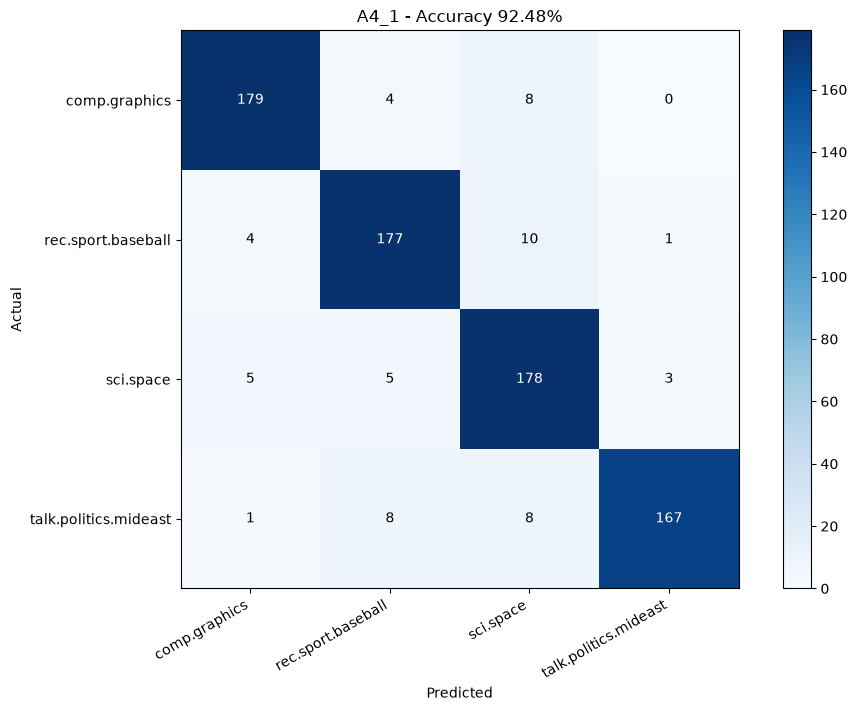

In [7]:
from scipy.sparse import csr_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt

clf = LogisticRegression(max_iter=1000, random_state=42)
with threadpool_limits(limits=2):
    clf.fit(csr_matrix(X_train), y_train)
    y_pred = clf.predict(csr_matrix(X_test))
labels = np.arange(len(target_names))
cm = confusion_matrix(y_test, y_pred, labels=labels)
report = classification_report(y_test, y_pred, labels=labels,
                               target_names=target_names, output_dict=True, zero_division=0)
classifier_results = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "macro_f1": float(f1_score(y_test, y_pred, average="macro")),
    "correct": int(np.count_nonzero(y_test == y_pred)),
    "test_documents": int(len(y_test)), "iterations": clf.n_iter_.tolist(),
    "confusion_matrix": cm.tolist(), "classification_report": report,
}
assert cm.sum() == len(y_test)
assert np.array_equal(cm.sum(axis=1), np.bincount(y_test, minlength=len(labels)))
print(f"Accuracy: {classifier_results['accuracy']:.4%}; Macro-F1: {classifier_results['macro_f1']:.6f}")
print(f"Correct: {classifier_results['correct']}/{len(y_test)}, iterations: {clf.n_iter_.tolist()}")
print(f"{'class':28} {'precision':>10} {'recall':>10} {'F1':>10} {'support':>8}")
for name in target_names:
    row = report[name]
    print(f"{name:28} {row['precision']:10.4f} {row['recall']:10.4f} {row['f1-score']:10.4f} {row['support']:8.0f}")

fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
heatmap = ax.imshow(cm, cmap="Blues")
fig.colorbar(heatmap, ax=ax)
ax.set(title=f"A4_1 - Accuracy {classifier_results['accuracy']:.2%}",
       xlabel="Predicted", ylabel="Actual", xticks=labels, yticks=labels,
       xticklabels=target_names, yticklabels=target_names)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
for i in labels:
    for j in labels:
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=140)
plt.show()
plt.close(fig)


## 3. · BoW 한계와 실제 오분류 5건

오분류를 Test의 문서 ID 오름차순으로 선택합니다. 선형 모델의 예측 클래스와 실제 클래스 점수 차이는

$$\Delta=(b_{\hat y}-b_y)+\sum_t x_t(w_{\hat y,t}-w_{y,t})$$

로 분해됩니다. 양수 기여는 예측 클래스를, 음수 기여는 실제 클래스를 지지합니다.
이는 모델 점수의 분해이며 원인에 대한 설명은 본문·레이블과 함께 검토한 **가설**입니다.
공개 출력은 원문 단어 대신 feature ID를 사용합니다.


In [8]:
errors = np.flatnonzero(y_pred != y_test)
assert len(errors) >= 5, "미션의 실제 오분류 5건 분석을 위해 사례를 확인하세요."
misclassified_examples = []
with threadpool_limits(limits=2):
    decision_scores = clf.decision_function(csr_matrix(X_test))
for doc_id in errors[:5]:
    actual, predicted = int(y_test[doc_id]), int(y_pred[doc_id])
    contribution = X_test[doc_id] * (clf.coef_[predicted] - clf.coef_[actual])
    intercept_difference = float(clf.intercept_[predicted] - clf.intercept_[actual])
    margin = float(contribution.sum() + intercept_difference)
    assert np.isclose(margin, decision_scores[doc_id, predicted] - decision_scores[doc_id, actual])
    assert margin >= 0
    positive = np.flatnonzero(contribution > 0)
    negative = np.flatnonzero(contribution < 0)
    example = {
        "test_doc_id": int(doc_id), "actual": target_names[actual],
        "predicted": target_names[predicted], "decision_margin": margin,
        "intercept_difference": intercept_difference,
        "top_predicted_features": [{"feature_id": int(i), "contribution": float(contribution[i])}
                                   for i in positive[np.argsort(-contribution[positive])][:3]],
        "top_actual_features": [{"feature_id": int(i), "contribution": float(contribution[i])}
                                for i in negative[np.argsort(contribution[negative])][:3]],
    }
    misclassified_examples.append(example)
print(json.dumps(misclassified_examples, ensure_ascii=False, indent=2))
classifier_results["misclassified_examples"] = misclassified_examples

# 직접 작성한 문장으로 어순 손실과 부정어 제거를 확인합니다.
from collections import Counter
assert Counter(preprocessor.tokenize("dog bites man")) == Counter(preprocessor.tokenize("man bites dog"))
assert preprocessor.tokenize("not good") == preprocessor.tokenize("good")
print("BoW toy checks PASS: order ignored; stopword removal can lose negation.")


[
  {
    "test_doc_id": 3,
    "actual": "talk.politics.mideast",
    "predicted": "sci.space",
    "decision_margin": 0.012344362070372927,
    "intercept_difference": 0.24608200243726525,
    "top_predicted_features": [
      {
        "feature_id": 15423,
        "contribution": 0.2409305076513161
      },
      {
        "feature_id": 28266,
        "contribution": 0.09139081884201032
      },
      {
        "feature_id": 12488,
        "contribution": 0.07884023703863567
      }
    ],
    "top_actual_features": [
      {
        "feature_id": 22063,
        "contribution": -0.3579732149177813
      },
      {
        "feature_id": 23118,
        "contribution": -0.14448868179193305
      },
      {
        "feature_id": 17447,
        "contribution": -0.14135362946396582
      }
    ]
  },
  {
    "test_doc_id": 5,
    "actual": "comp.graphics",
    "predicted": "sci.space",
    "decision_margin": 0.4277560840831387,
    "intercept_difference": 0.13028533083220814,
    "top_pre

### 검토한 실제 사례의 문맥과 개선 가설

아래 표는 고정 데이터·분할의 검토한 사례입니다. 위에서 재계산한 ID·레이블·점수 차이와 대조합니다.

아래 ID는 Test 목록의 0 기반 인덱스입니다. 설명은 실제 본문과 선형 모델의 클래스 점수 차이를 근거로 한 원인 가설입니다. 기여도는 $x_t(w_{pred,t}-w_{true,t})$로 계산하며 양수이면 예측 클래스를 지지합니다. 전체 점수 차이는 기여도 합에 절편 차이를 더한 값입니다. 인명은 본문 발췌에서 생략했습니다.

| Test ID | 실제 → 예측 | 본문 근거 | 기여도 및 분석 |
| --- | --- | --- | --- |
| 3 | mideast → space | `palestinian police force`, `concrete proposals`, `idea` | `palestinian` -0.3580, `police` -0.1445가 실제 클래스를 지지했지만 `idea` +0.2409 등 일반 어휘와 절편 +0.2461이 합쳐져 space가 0.0123 앞섰습니다. 정치적 구문의 관계를 독립 단어 가중치만으로 충분히 표현하기 어렵다는 가설입니다. |
| 5 | graphics → space | `What is 9 x 6?`, `base 13 system` | `system` +0.1815, `base` +0.0935가 space를 지지했습니다. 한 글자 `9`, `x`, `6`은 정규식에서 사라집니다. 게시글 대화 맥락과 그래픽 주제 단서가 부족한 짧은 문서의 오류입니다. |
| 13 | graphics → baseball | `RS6000 compiler`, `COBOL`, `pascal` | `pascal` -0.0931, `compiler` -0.0895가 실제 클래스를 지지했지만 잔존 서명 토큰 +0.2122와 `think` +0.1741이 다른 클래스를 밀었습니다. 서명 제거의 불완전성과 이름·일반 단어의 우연한 상관관계가 드러납니다. |
| 19 | baseball → space | `SI`, `article`, `subscription`, `date` | `si` +0.1221, `date` +0.0700이 space를 지지했고 최종 점수 차이는 0.0233입니다. 약어의 의미와 기사 대상의 문맥을 unigram만으로 복원하기 어려운 사례입니다. |
| 25 | mideast → space | `What are you stupid?` | 불용어 제거 후 `stupid`만 남습니다. 이 단어의 기여도는 -0.1325지만 절편 차이 +0.2461이 커 최종 space 점수가 0.1136 앞섰습니다. 주제 정보가 거의 없는 짧은 문서에서 클래스 기본 경향에 의존합니다. |

### 표현 방식의 한계와 개선 실험

`dog bites man`과 `man bites dog`는 같은 빈도로 표현돼 주어·목적어의 차이를 잃습니다. `bank`와 `사과` 같은 다의어는 하나의 차원에 합쳐지고 `car`와 `automobile` 같은 동의어는 다른 차원에 나뉩니다. 위 실제 사례에서는 짧은 문서, 약어, 잔존 서명과 전처리 손실을 확인했습니다. 각 사례의 개선 여부는 추가 실험으로 검증해야 합니다.

후속 비교는 부정어 보존, 도메인 토큰 정규식, bigram, 문맥 임베딩 또는 Transformer 모델을 대상으로 합니다. 같은 분할에서 Accuracy·Macro-F1을 비교하고, 관련도 정답이 있는 평가 쿼리로 Precision@5와 nDCG@5를 측정해야 합니다. 현재 검색 결과의 주제 적합성과 순위 변화는 관찰했으며 검색 품질 정답셋은 구축 대기 상태입니다.

백만 문서·어휘 5만 개의 dense float64 행렬은 원소만 약 400GB가 필요합니다. 희소 저장·역색인·후보 가지치기·캐시를 비교하고 인덱스 구축 비용과 질의 지연 p50/p95를 나눠 측정하는 방향입니다.


In [9]:
reviewed_ids = [3, 5, 13, 19, 25]
actual_ids = [row["test_doc_id"] for row in misclassified_examples]
assert actual_ids == reviewed_ids, "데이터·분할이 달라졌습니다. 설명 표를 현재 오분류로 다시 검토하세요."
print("Reviewed case IDs match recomputed errors:", actual_ids)


Reviewed case IDs match recomputed errors: [3, 5, 13, 19, 25]


## 구술 평가 대비 · Q1~Q5

각 문항은 핵심 답변 3줄 요약과 수식·코드 근거로 구성했습니다. 기존 로컬 실측 수치는 참고 기준이며 이 노트북의 실제 결과는 앞의 실행 셀과 마지막 요약에서 확인합니다.

## Q1. 토큰화의 목적과 언어별 처리 방식은 무엇인가

### 핵심 답변 3줄 요약

1. 토큰화는 텍스트를 집계 가능한 단위로 나눠 어휘 사전과 TF 행렬을 만드는 과정입니다.
2. 영어는 공백과 구두점을 기준으로 시작할 수 있고, 한국어는 조사와 어미를 고려한 형태소 분석이 단어 변형을 묶는 데 도움이 됩니다.
3. 이 프로젝트는 소문자화 후 Unicode 단어 문자 두 개 이상의 토큰을 추출하며 sklearn 검증에도 같은 함수를 전달합니다.

### 수식과 코드 근거

문서 $d$를 토큰열 $T(d)$로 바꾸면 $tf(d,t)=\sum_{u\in T(d)}\mathbf{1}[u=t]$입니다. 실제 전처리 클래스로 토큰 규칙을 확인할 수 있습니다.

```python
# 이 노트북에서 정의한 TextPreprocessor 사용

tokens = TextPreprocessor(stopwords=set()).tokenize("Space, SATELLITE! a 3D_x")
assert tokens == ["space", "satellite", "3d_x"]
```

이 예제에서는 한 글자 `a`가 제거되고 `3d_x`는 남습니다. 한국어의 `학교`, `학교에`, `학교에서`는 공백 토큰화 시 서로 다른 토큰이 될 수 있습니다. 형태소 분석으로 `학교`를 공통 단위로 묶을 때 어휘 크기와 OOV 비율이 달라집니다. 한국어에 적용할 경우 분석기·버전을 고정하고 같은 분할에서 성능을 비교해야 합니다.

`TextPreprocessor.tokenize`가 소문자화·정규식 추출·불용어 제거를 수행합니다. 불용어 123개는 이 노트북의 STOPWORDS_TEXT에 내장되어 실행 폴더가 바뀌어도 같은 목록을 사용합니다. [전처리 구현](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/src/preprocess.py), [고정 불용어 목록](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/resources/stopwords_en.txt)

## Q2. TF, IDF, TF-IDF의 정의와 역할은 무엇인가

### 핵심 답변 3줄 요약

1. TF는 문서 안의 단어 빈도이며 IDF는 여러 문서에서 흔한 단어의 가중치를 낮춥니다.
2. Smooth IDF는 $\ln((1+N)/(1+df))+1$이며 TF와 곱한 후 문서별 L2 정규화를 적용합니다.
3. Train에서 학습한 어휘·IDF를 Test와 쿼리에 적용하고, 동일 설정의 sklearn 결과와 `1e-6` 이내 오차인지 비교합니다.

### 수식과 코드 근거

$$tf(d,t)=c_{d,t},\quad df(t)=\sum_d\mathbf{1}[c_{d,t}>0]$$
$$idf(t)=\ln\left(\frac{1+N}{1+df(t)}\right)+1,\quad X_{d,t}=tf(d,t)idf(t)$$

로그는 문서 빈도 역수의 차이를 완만하게 만들어 드문 단어의 가중치가 지나치게 커지는 것을 줄입니다. Smoothing은 분모를 안정화하며 `+1`은 모든 Train 문서에 있는 단어의 IDF를 1로 유지합니다. 다음은 두 문서와 두 단어의 설명용 계산입니다.

```python
import numpy as np

counts = np.array([[2, 1], [0, 1]], dtype=np.float64)
df = np.count_nonzero(counts, axis=0)
idf = np.log((1 + len(counts)) / (1 + df)) + 1
weighted = counts * idf
norms = np.linalg.norm(weighted, axis=1, keepdims=True)
normalized = np.divide(
    weighted, norms, out=np.zeros_like(weighted), where=norms != 0
)
assert np.allclose(idf, [1.4054651081081644, 1.0])
assert normalized.shape == (2, 2)
```

첫 단어는 한 문서에만 있어 IDF가 약 1.405465이고, 두 번째 단어는 두 문서에 모두 있어 1입니다. 행렬의 각 행은 문서, 각 열은 학습 어휘의 단어이므로 shape는 `(N, |V|)`입니다. Test 문서 수가 $M$이면 변환 결과는 `(M, |V|)`가 됩니다.

실제 참조 설정은 `smooth_idf=True`, `sublinear_tf=False`, `norm='l2'`, `dtype=np.float64`와 공통 callable analyzer `TextPreprocessor.tokenize`입니다. 검증 스크립트는 어휘 열 순서·TF·DF·IDF와 Train/Test/쿼리 벡터를 비교하고 허용 오차 `1e-6`을 초과하면 실패합니다. [NumPy 벡터라이저](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/src/tfidf.py), [단계별 검증](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/verify_tfidf.py)

로컬 실측에서 어휘 크기는 33,297이며 Train shape는 `(3029, 33297)`, Test shape는 `(758, 33297)`입니다. Train 최대 오차는 `2.3315e-15`, Test 최대 오차는 `8.3267e-16`, 검증 쿼리 다섯 건의 최대 오차와 IDF 오차는 0입니다. 모두 미션의 `1e-6` 기준을 통과했습니다. [실측 검증 결과](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/artifacts/tfidf_verification.json)

## Q3. 코사인 유사도는 내적과 정규화로 어떻게 계산하는가

### 핵심 답변 3줄 요약

1. 코사인은 두 벡터의 내적을 각 벡터의 L2 길이 곱으로 나눠 방향의 유사도를 계산합니다.
2. L2 정규화된 문서와 쿼리는 `D @ q`로 점수를 계산하며, 0벡터는 별도 처리합니다.
3. 문서 길이에 따른 크기 차이를 줄이고 상위 5개를 반환하되, 관련도 정답으로 실제 검색 품질도 확인해야 합니다.

### 수식과 코드 근거

$$\cos(x,q)=\frac{\sum_t x_tq_t}{\sqrt{\sum_t x_t^2}\sqrt{\sum_t q_t^2}}=\hat{x}\cdot\hat{q}$$

```python
import numpy as np

x = np.array([3.0, 4.0])
q = np.array([0.0, 2.0])
score = (x @ q) / (np.linalg.norm(x) * np.linalg.norm(q))
assert np.isclose(score, 0.8)
assert np.isclose((x / np.linalg.norm(x)) @ (q / np.linalg.norm(q)), 0.8)
```

내적 8을 길이 곱 10으로 나눠 유사도 0.8이 됩니다. 원시 유클리드 거리는 문서 길이에 따라 달라집니다. 단위 벡터에서는 $\|\hat{x}-\hat{q}\|^2=2-2\cos(x,q)$이므로 두 기준이 같은 순위를 줄 수 있습니다. OOV만 있는 쿼리는 정규화 분모가 0이므로 영벡터를 유지하고 빈 결과를 반환합니다. 검색 결과는 양수 점수만 포함하고 점수 내림차순·동점 문서 ID 오름차순으로 정렬합니다. [검색과 순위 구현](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/src/search_engine.py)

### 백만 문서로 확장한다면

Dense `float64` TF-IDF 행렬은 $8N|V|$ 바이트가 필요합니다. $N=10^6$, $|V|=50,000$이면 원소 저장에만 400GB, 약 372.5GiB가 필요하고 질의당 전체 스캔은 $O(N|V|)$입니다. 희소 행렬과 역색인으로 쿼리 단어의 posting만 순회하고 후보 Top-K를 계산하는 방식으로 확장할 수 있습니다. 인덱스 업데이트, 캐시와 동시 질의 처리도 함께 설계해야 합니다. 구축 시간·메모리·질의 지연 p50/p95를 측정하고 동일 쿼리에서 품질과 점수 동치성을 확인해야 합니다.

## Q4. BoW가 문맥과 어순을 잃는 한계는 무엇인가

### 핵심 답변 3줄 요약

1. Unigram BoW는 단어 빈도를 집계하므로 동일 단어를 다른 순서로 배치해도 같은 벡터가 됩니다.
2. 다의어는 하나의 열로 합쳐지고 동의어는 다른 열로 나뉘어 의미와 벡터 유사도가 어긋날 수 있습니다.
3. 실제 오분류 문서 5건에서 원문·레이블·기여 단어를 대조한 뒤 bigram과 문맥 모델의 개선 효과를 측정해야 합니다.

### 수식과 코드 근거

```python
from collections import Counter

a = Counter("dog bites man".split())
b = Counter("man bites dog".split())
assert a == b
```

같은 어휘 빈도에 같은 IDF를 곱하므로 TF-IDF도 같습니다. 반면 주어와 목적어가 바뀌어 의미는 달라집니다. `not good`에서 `not`을 불용어로 제거하면 `good`만 남아 부정이 사라질 수 있습니다. 이 예제는 한계를 설명하기 위한 구성 사례입니다.

분류기는 `LogisticRegression(max_iter=1000, random_state=42)`로 학습하고 Test의 Accuracy·Macro-F1·혼동 행렬과 실제 오분류 다섯 건의 수치를 저장합니다. 공개 JSON에는 Test 문서 ID, 실제·예측 레이블, 기여 feature ID와 기여도, 절편 차이를 기록합니다. 아래 분석의 단어와 문맥은 검토한 비식별 사례를 근거로 설명합니다. [분류 및 오분류 추출 구현](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/src/classifier.py)

로컬 실측은 Test 758건 중 701건 정답으로 Accuracy `92.4802%`, Macro-F1 `0.925329`입니다. 아래 사례는 실제 Test 오분류를 바탕으로 해석한 원인 가설입니다. 게시물의 실제 범주와 본문의 주제가 어긋나거나 앞선 대화에 의존할 수 있으므로 개선 효과는 재실험으로 확인해야 합니다. [분류 지표와 추출 사례](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/artifacts/classifier_metrics.json)

선형 모델에서 예측 클래스와 실제 클래스의 점수 차이는 다음과 같이 분해됩니다. 양수 단어 기여는 예측 클래스를, 음수 기여는 실제 클래스를 지지합니다. 기여도는 모델의 선형 점수 단위입니다.

$$\Delta=(b_{\hat y}-b_y)+\sum_t x_t(w_{\hat y,t}-w_{y,t})$$

| Test ID | 실제 → 예측 | 실측 기여와 BoW 원인 해석 |
| --- | --- | --- |
| 3 | talk.politics.mideast → sci.space | `palestinian police force` 제안을 묻는 짧은 글입니다. `palestinian` −0.3580에도 `idea` +0.2409, `stage` +0.0914, `fit` +0.0788과 절편 차이 +0.2461이 작용해 최종 차이가 +0.0123입니다. 범용 단어의 합이 정치 문맥을 충분히 표현하지 못한 사례입니다. |
| 5 | comp.graphics → sci.space | `9 x 6`, `base 13`을 언급하는 짧은 참조입니다. `system` +0.1815, `base` +0.0935가 예측을 지지하며 최종 차이는 +0.4278입니다. 직접적인 그래픽 어휘와 대화·문화적 문맥이 부족합니다. |
| 13 | comp.graphics → rec.sport.baseball | compiler·COBOL·Pascal 관련 농담입니다. `compiler` −0.0895보다 이름 토큰 +0.2122, `think` +0.1741 등 공유 표현의 영향이 커 최종 차이가 +0.2199입니다. 남은 서명과 일반 표현의 우연한 연관이 오판에 기여했습니다. 문서에는 이름 토큰을 가려 기재했습니다. |
| 19 | rec.sport.baseball → sci.space | 과거 잡지 기사 날짜를 묻습니다. `si` +0.1221, `date` +0.0700과 절편 차이 +0.0771 등이 작용해 최종 차이는 +0.0233입니다. 짧은 약어와 이전 대화 맥락을 빈도만으로 해석하기 어렵습니다. |
| 25 | talk.politics.mideast → sci.space | 짧은 반문에서 전처리 후 한 토큰만 남습니다. 해당 토큰 기여 −0.1325보다 절편 차이 +0.2461이 커 최종 차이는 +0.1136입니다. 주제 어휘의 희소성 때문에 절편의 영향이 상대적으로 커졌습니다. |

위 M4 실행 셀에 이번 학습의 혼동 행렬이 내장되어 있습니다.

### 사과 검색에서 과일·기업·용서 문서가 섞인다면

같은 표면형 `사과`가 하나의 차원에 매핑돼 의도를 구분하기 어렵습니다. 주변 단어를 반영하는 n-gram, 질의 확장 또는 명확화, 문맥 임베딩을 비교할 수 있습니다. 단일 단어 쿼리의 의도가 불명확한 경우에는 사용자에게 의미 선택을 제공하는 방식도 가능합니다.

### 재구현과 검색 품질 평가

관련도 정답이 있는 평가 쿼리 집합을 만들고 `Precision@5 = Top-5 중 관련 문서 수 / 5`와 순위별 관련도를 반영한 nDCG@5를 측정합니다. 예를 들어 결과 다섯 건 중 네 건이 관련 문서이면 Precision@5는 0.8입니다. 같은 학습·평가 분할을 유지하면서 unigram, bigram, BM25, 문맥 모델을 비교하고 개선 선택에는 질의 지연도 함께 고려합니다. 분류 성능은 Accuracy와 Macro-F1, 클래스별 혼동 행렬로 별도 측정합니다.

## Q5. 전처리 기준은 어떤 근거로 설계했는가

### 핵심 답변 3줄 요약

1. 소문자화와 두 글자 이상 단어 정규식으로 표기 변동과 일부 잡음을 줄이며 참조 구현과 같은 토큰열을 사용합니다.
2. 불용어 목록은 노트북 안의 고정 문자열로 관리하고 부정어·도메인 핵심어의 정보 손실을 검토합니다.
3. Train 전용 어휘·IDF 학습과 공통 전처리 함수로 데이터 누수를 차단하고 변경 효과를 재현 가능하게 비교합니다.

### 수식과 코드 근거

```python
import re

# 규칙을 설명하기 위한 작은 불용어 집합입니다.
stopwords = {"the", "and"}
text = "The SPACE and satellite."
tokens = [t for t in re.findall(r"(?u)\b\w\w+\b", text.lower())
          if t not in stopwords]
assert tokens == ["space", "satellite"]
```

이 규칙에서 한 글자 `R`과 `C++`는 사라질 수 있으며, 숫자와 밑줄은 단어 문자로 취급됩니다. 따라서 실제 데이터의 도메인 용어를 확인하고 정규식 변경 전후 어휘 크기, OOV 비율, Macro-F1과 검색 품질을 비교해야 합니다. 현재 내장 불용어 목록에는 `no`, `nor`, `not`도 포함돼 부정 의미를 잃을 수 있습니다. 사용자가 제공한 123개 단어를 프로젝트 기준 `a4-1-en-v1`로 채택했고, 기능어를 줄이는 선정 근거와 LF 정규화 해시를 기록했습니다. 외부 목록의 원출처는 미확인입니다. 동의어 치환은 적용하지 않습니다. [불용어 목록](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/resources/stopwords_en.txt), [선정 근거와 해시](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/docs/A4_1_data_sources.md)

### 모듈을 분리하는 이유와 새 데이터셋 적용

전처리는 토큰열 생성, 벡터화는 어휘·IDF 학습과 변환, 검색은 점수와 순위 계산, 분류는 모델 학습과 평가를 담당하도록 나눕니다. 같은 전처리와 벡터 표현을 검색과 분류에서 재사용하고 단계별 오류를 확인할 수 있기 때문입니다.

새 데이터셋에서는 데이터 로드 셀의 `(문서, 레이블)` 입력 규격과 tokenizer를 교체해 벡터화·검색 코드를 재사용할 수 있습니다. 현재 카테고리는 `CATEGORIES`, 캐시 경로는 `DATA_HOME`으로 지정하며 기본값은 현재 폴더의 `artifacts/data_cache`입니다. 데이터 로더는 헤더·푸터·인용문 제거, 이메일·일반 전화번호 형식 마스킹, 빈 본문 제외 후 층화 8:2 분할을 수행합니다. `random_state=42`, 클래스별 건수와 코퍼스 해시를 메타데이터에 저장합니다. [데이터 로더](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/src/dataset.py)

실측 데이터는 원본 3,894건에서 빈 본문 107건을 제외한 3,787건이며 Train 3,029건, Test 758건입니다. 카테고리 순서별 Test 건수는 `[191, 192, 191, 184]`입니다. [데이터 메타데이터](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/artifacts/dataset_metadata.json)

사용 중인 sklearn 다운로드 file ID `5975967`과 일치하는 Figshare 배포 항목에서 CC BY 4.0을 확인했습니다. 등록 저자·DOI·라이선스 링크와 프로젝트의 수정 내용을 출처 보고서에 기록했습니다. [데이터 출처와 이용 조건 확인](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/docs/A4_1_data_sources.md)

선행 이슈 #8 검수 보고서에서 집계한 전체 사용 문서 3,787건의 자동 검사에서는 이메일 0건, 전화번호 후보 0건, 인명·제목 형태 후보 18,426건이 검출됐습니다. 후보가 있는 문서는 2,292건입니다. 대문자 단어열에는 제목과 기관명도 포함될 수 있고, 소문자 이름이나 다른 식별 정보를 놓칠 수 있습니다. 이 결과와 자동 마스킹 적용 범위를 설명하고 인명·서명 전체 수동 검수를 이어가야 합니다. [자동 검사 결과](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/artifacts/privacy_audit.json), [검수 실행 계획](https://github.com/ntt65/A4_1/blob/feat/a4-1-single-notebook/docs/A4_1_data_review_plan.md)


## 보너스 과제 구현 및 검증

필수 평가와 분리해 세 가지 확장을 검증합니다.

1. **TF 변형**: 동일한 Train 어휘·IDF와 분할에서 Raw, Log, Double TF의 분류 지표와 검색 순위를 비교합니다.
2. **BM25**: 작은 예제의 수작업 결과와 비교한 뒤 실제 질의를 검색합니다.
3. **역색인**: TF-IDF와 BM25 각각의 전체 점수 계산과 역색인이 같은 점수·Top-5를 반환하는지 확인합니다.

\[
tf_{\mathrm{raw}}=c,\quad tf_{\log}=\ln(1+c),\quad
tf_{\mathrm{double}}=
\begin{cases}K+(1-K)c/c_{\max},&c>0\\0,&c=0.\end{cases}
\]

Double TF는 $K=0.5$를 사용합니다. 존재하지 않는 단어와 빈 문서는 계속 0이어야 합니다. 모든 변형에서 같은 IDF를 곱하고 L2 정규화합니다. 검색 순위 겹침과 역색인 순위 일치는 **관련성 정답에 대한 검색 품질 지표가 아닙니다**.

Log TF는 반복 빈도의 영향을 완화하고 Double TF는 문서 내 최빈 단어를 기준으로 상대 빈도를 계산합니다. 아래 실측 Accuracy/Macro-F1과 Raw 대비 Top-5 겹침을 함께 보고 변화의 방향을 해석합니다. 겹침률만으로 검색 정확도가 개선됐다고 결론 내리지 않습니다.

In [10]:
from collections import Counter
from statistics import median
from time import perf_counter
from scipy.sparse import csr_matrix, vstack
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from threadpoolctl import threadpool_limits
import math

BONUS_QUERIES = [
    "space satellite launch orbit",
    "computer graphics rendering image",
    "baseball pitcher season game",
    "middle east peace politics",
]
BONUS_EQUIVALENCE_QUERIES = [
    *BONUS_QUERIES, "", "zzzzunseenquerytoken", "space space satellite",
]

def BonusRank(scores, top_k=5):
    if isinstance(top_k, bool) or not isinstance(top_k, (int, np.integer)):
        raise TypeError("top_k must be an integer")
    if top_k <= 0:
        raise ValueError("top_k must be positive")
    scores = np.asarray(scores, dtype=np.float64).ravel()
    candidates = np.flatnonzero(scores > 0)
    if len(candidates) > top_k:
        boundary = np.partition(scores[candidates], -top_k)[-top_k]
        candidates = candidates[scores[candidates] >= boundary]
    return candidates[np.lexsort((candidates, -scores[candidates]))][:top_k]

def BonusTf(counts, variant="raw", K=0.5):
    values = np.array(counts, dtype=np.float64, copy=True)
    if variant == "log":
        np.log1p(values, out=values)
    elif variant == "double":
        if not 0 <= K <= 1:
            raise ValueError("K must be between 0 and 1")
        for row in values:
            present = row > 0
            maximum = row.max(initial=0.0)
            if maximum > 0:
                row[present] = K + (1 - K) * row[present] / maximum
    elif variant != "raw":
        raise ValueError("variant must be raw, log, or double")
    return values

bonus_toy_counts = np.array([[0., 1., 3.], [0., 0., 0.]])
bonus_toy_variants = {
    variant: BonusTf(bonus_toy_counts, variant)
    for variant in ("raw", "log", "double")
}
np.testing.assert_allclose(bonus_toy_variants["double"], [[0., 2/3, 1.], [0., 0., 0.]])
for values in bonus_toy_variants.values():
    assert np.all(values[bonus_toy_counts == 0] == 0)
assert BonusRank([0.4, 0.4, 0.4], 2).tolist() == [0, 1]
assert BonusRank([0., 0.], 5).tolist() == []
print("TF toy counts:", bonus_toy_counts.tolist())
for variant, values in bonus_toy_variants.items():
    print(variant, values.tolist())
print("Absent-term/empty-document/Top-K tie checks: PASS")

TF toy counts: [[0.0, 1.0, 3.0], [0.0, 0.0, 0.0]]
raw [[0.0, 1.0, 3.0], [0.0, 0.0, 0.0]]
log [[0.0, 0.6931471805599453, 1.3862943611198906], [0.0, 0.0, 0.0]]
double [[0.0, 0.6666666666666666, 1.0], [0.0, 0.0, 0.0]]
Absent-term/empty-document/Top-K tie checks: PASS


In [11]:
def BonusVariantBlock(documents, variant):
    values = BonusTf(vectorizer.count_matrix(documents), variant)
    values *= vectorizer.idf_
    norms = np.linalg.norm(values, axis=1, keepdims=True)
    np.divide(values, norms, out=values, where=norms != 0)
    return values

def BonusSparseVariant(documents, variant, block_size=128):
    # Keep only one small dense block while constructing a sparse training matrix.
    blocks = [
        csr_matrix(BonusVariantBlock(documents[start:start + block_size], variant))
        for start in range(0, len(documents), block_size)
    ]
    return vstack(blocks, format="csr")

bonus_results = {"tf_variants": {}}
with threadpool_limits(limits=2):
    for variant in ("raw", "log", "double"):
        bonus_train = csr_matrix(X_train) if variant == "raw" else BonusSparseVariant(train_docs, variant)
        bonus_test = csr_matrix(X_test) if variant == "raw" else BonusSparseVariant(test_docs, variant)
        bonus_clf = LogisticRegression(max_iter=1000, random_state=42)
        bonus_clf.fit(bonus_train, y_train)
        bonus_prediction = bonus_clf.predict(bonus_test)
        bonus_rankings = {}
        for query in BONUS_QUERIES:
            query_vector = BonusVariantBlock([query], variant)[0]
            scores = np.asarray(bonus_train @ query_vector).ravel()
            bonus_rankings[query] = [
                {"doc_id": int(i), "score": float(scores[i])}
                for i in BonusRank(scores)
            ]
        bonus_results["tf_variants"][variant] = {
            "accuracy": float(accuracy_score(y_test, bonus_prediction)),
            "macro_f1": float(f1_score(y_test, bonus_prediction, average="macro")),
            "search_results": bonus_rankings,
        }
        del bonus_train, bonus_test, bonus_clf
for variant, values in bonus_results["tf_variants"].items():
    overlaps = {}
    for query in BONUS_QUERIES:
        raw_ids = {item["doc_id"] for item in bonus_results["tf_variants"]["raw"]["search_results"][query]}
        variant_ids = {item["doc_id"] for item in values["search_results"][query]}
        overlaps[query] = len(raw_ids & variant_ids) / len(raw_ids) if raw_ids else 1.0
    values["top5_overlap_with_raw"] = overlaps
    print(f"{variant:6s} accuracy={values['accuracy']:.6f}  "
          f"macro_f1={values['macro_f1']:.6f}  "
          f"mean_top5_overlap={np.mean(list(overlaps.values())):.2%}")

bonus_raw_metrics = bonus_results["tf_variants"]["raw"]
for variant, values in bonus_results["tf_variants"].items():
    print(f"{variant}: accuracy delta={values['accuracy'] - bonus_raw_metrics['accuracy']:+.6f}, "
          f"macro_f1 delta={values['macro_f1'] - bonus_raw_metrics['macro_f1']:+.6f}")
    for query in BONUS_QUERIES:
        doc_ids = [item["doc_id"] for item in values["search_results"][query]]
        print(f"  {query!r}: Top-5={doc_ids}, raw overlap={values['top5_overlap_with_raw'][query]:.0%}")

raw    accuracy=0.924802  macro_f1=0.925329  mean_top5_overlap=100.00%
log    accuracy=0.924802  macro_f1=0.925139  mean_top5_overlap=65.00%
double accuracy=0.919525  macro_f1=0.919962  mean_top5_overlap=55.00%
raw: accuracy delta=+0.000000, macro_f1 delta=+0.000000
  'space satellite launch orbit': Top-5=[1934, 2609, 755, 2145, 1725], raw overlap=100%
  'computer graphics rendering image': Top-5=[2876, 2389, 1315, 2515, 884], raw overlap=100%
  'baseball pitcher season game': Top-5=[7, 2549, 701, 2398, 621], raw overlap=100%
  'middle east peace politics': Top-5=[565, 2670, 1208, 2698, 171], raw overlap=100%
log: accuracy delta=+0.000000, macro_f1 delta=-0.000190
  'space satellite launch orbit': Top-5=[1725, 2145, 1096, 1700, 755], raw overlap=60%
  'computer graphics rendering image': Top-5=[2389, 2876, 1315, 2166, 1722], raw overlap=60%
  'baseball pitcher season game': Top-5=[7, 2549, 621, 2749, 1103], raw overlap=60%
  'middle east peace politics': Top-5=[565, 1208, 2670, 2698, 1

### BM25의 수식과 수작업 대조

\[
idf_{\mathrm{BM25}}(t)=\ln\left(1+\frac{N-df(t)+0.5}{df(t)+0.5}\right)
\]
\[
s(D,Q)=\sum_{t\in Q}\,idf(t)
\frac{f_{t,D}(k_1+1)}
{f_{t,D}+k_1(1-b+b|D|/\mathrm{avgdl})}.
\]

여기서는 $k_1=1.5$, $b=0.75$이며 $Q$는 전처리한 질의의 고유 단어 집합입니다. 같은 질의 단어가 반복돼도 각 단어는 한 번만 기여합니다. 문서 길이와 DF는 공통 전처리 이후 Train에서 계산합니다. 빈 문서와 OOV 질의는 0점을 반환합니다.

Toy 문서는 직접 작성한 `["cat","sat","sat"]`, `["cat","dog"]`, `["dog"]`입니다. $N=3$, 평균 길이 2, $df(cat)=2$, $df(sat)=1$을 수식에 직접 대입한 결과와 비교합니다.

In [12]:
class BonusBM25:
    def __init__(self, corpus_tokens, k1=1.5, b=0.75):
        if not np.isfinite(k1) or k1 <= 0 or not np.isfinite(b) or not 0 <= b <= 1:
            raise ValueError("BM25 requires k1 > 0 and 0 <= b <= 1")
        self.k1, self.b = k1, b
        self.doc_freqs = [dict(Counter(tokens)) for tokens in corpus_tokens]
        self.n_docs = len(self.doc_freqs)
        self.lengths = np.array([sum(freqs.values()) for freqs in self.doc_freqs], dtype=np.float64)
        self.avgdl = float(self.lengths.mean()) if self.n_docs else 0.0
        df = Counter(term for freqs in self.doc_freqs for term in freqs)
        self.idf = {
            term: float(np.log1p((self.n_docs - count + 0.5) / (count + 0.5)))
            for term, count in df.items()
        }
        self.penalty = (
            self.k1 * (1 - self.b + self.b * self.lengths / self.avgdl)
            if self.avgdl else np.zeros(self.n_docs)
        )
        self.postings = {}
        for doc_id, freqs in enumerate(self.doc_freqs):
            for term, count in freqs.items():
                self.postings.setdefault(term, []).append((doc_id, count))
        self.postings = {
            term: (
                np.array([doc_id for doc_id, _ in entries], dtype=np.int64),
                np.array([count for _, count in entries], dtype=np.float64),
            )
            for term, entries in self.postings.items()
        }

    def full_scan(self, query_tokens):
        scores = np.zeros(self.n_docs, dtype=np.float64)
        if not self.avgdl:
            return scores
        for term in dict.fromkeys(query_tokens):
            if term not in self.idf:
                continue
            frequencies = np.array([freqs.get(term, 0) for freqs in self.doc_freqs], dtype=np.float64)
            numerator = self.idf[term] * frequencies * (self.k1 + 1)
            denominator = frequencies + self.penalty
            scores += np.divide(
                numerator, denominator, out=np.zeros_like(frequencies), where=denominator != 0,
            )
        return scores

    def inverted_scan(self, query_tokens):
        scores = np.zeros(self.n_docs, dtype=np.float64)
        if not self.avgdl:
            return scores
        # The query-term iteration and arithmetic order match the full scan.
        for term in dict.fromkeys(query_tokens):
            if term not in self.postings:
                continue
            doc_ids, frequencies = self.postings[term]
            numerator = self.idf[term] * frequencies * (self.k1 + 1)
            denominator = frequencies + self.penalty[doc_ids]
            scores[doc_ids] += np.divide(
                numerator, denominator, out=np.zeros_like(frequencies), where=denominator != 0,
            )
        return scores

bonus_bm25_toy = BonusBM25([["cat", "sat", "sat"], ["cat", "dog"], ["dog"]])
bonus_bm25_actual = bonus_bm25_toy.full_scan(["cat", "sat"])
bonus_cat_idf = math.log(1 + 1.5 / 2.5)
bonus_sat_idf = math.log(1 + 2.5 / 1.5)
bonus_bm25_expected = np.array([
    bonus_cat_idf * 2.5 / (1 + 1.5 * 1.375)
    + bonus_sat_idf * 5.0 / (2 + 1.5 * 1.375),
    bonus_cat_idf,
    0.,
])
np.testing.assert_allclose(bonus_bm25_actual, bonus_bm25_expected, atol=1e-12, rtol=0)
np.testing.assert_allclose(bonus_bm25_toy.inverted_scan(["cat", "sat"]), bonus_bm25_expected, atol=1e-12, rtol=0)
np.testing.assert_allclose(bonus_bm25_toy.full_scan(["cat", "cat"]), bonus_bm25_toy.full_scan(["cat"]), atol=1e-12, rtol=0)
assert not BonusBM25([[], []]).full_scan(["cat"]).any()
bonus_results["bm25_toy"] = {
    "expected_scores": bonus_bm25_expected.tolist(),
    "actual_scores": bonus_bm25_actual.tolist(),
    "max_absolute_error": float(np.max(np.abs(bonus_bm25_actual - bonus_bm25_expected))),
    "tolerance": 1e-12,
    "passed": True,
}
print("BM25 toy expected:", bonus_bm25_expected.tolist())
print("BM25 toy actual:  ", bonus_bm25_actual.tolist())
print(f"BM25 toy max absolute error: {bonus_results['bm25_toy']['max_absolute_error']:.4e}")
bonus_bm25_started = perf_counter()
bonus_bm25 = BonusBM25(preprocessor.tokenize(doc) for doc in train_docs)
bonus_bm25_build_seconds = perf_counter() - bonus_bm25_started
bonus_results["bm25_search_comparison"] = []
for query in BONUS_QUERIES:
    scores = bonus_bm25.full_scan(preprocessor.tokenize(query))
    bm25_results = [{"doc_id": int(i), "score": float(scores[i])} for i in BonusRank(scores)]
    comparison = {
        "query": query,
        "tfidf": bonus_results["tf_variants"]["raw"]["search_results"][query],
        "bm25": bm25_results,
    }
    bonus_results["bm25_search_comparison"].append(comparison)
    print(query)
    print("  TF-IDF:", [(r["doc_id"], round(r["score"], 4)) for r in comparison["tfidf"]])
    print("  BM25:  ", [(r["doc_id"], round(r["score"], 4)) for r in bm25_results])

BM25 toy expected: [1.5908508972825368, 0.47000362924573563, 0.0]
BM25 toy actual:   [1.5908508972825366, 0.4700036292457356, 0.0]
BM25 toy max absolute error: 2.2204e-16


space satellite launch orbit
  TF-IDF: [(1934, 0.4737), (2609, 0.3076), (755, 0.2954), (2145, 0.2932), (1725, 0.2701)]
  BM25:   [(755, 18.4891), (1934, 17.4089), (1725, 16.634), (186, 16.1086), (3027, 15.9852)]
computer graphics rendering image
  TF-IDF: [(2876, 0.4281), (2389, 0.4191), (1315, 0.3428), (2515, 0.2948), (884, 0.2548)]
  BM25:   [(2389, 22.754), (2697, 15.8957), (1722, 15.3135), (2065, 14.9988), (1107, 14.3585)]
baseball pitcher season game
  TF-IDF: [(7, 0.334), (2549, 0.2974), (701, 0.2792), (2398, 0.2517), (621, 0.2439)]
  BM25:   [(955, 14.9129), (1663, 13.6632), (784, 13.387), (852, 12.8049), (701, 12.6757)]
middle east peace politics
  TF-IDF: [(565, 0.2775), (2670, 0.155), (1208, 0.1481), (2698, 0.1421), (171, 0.1351)]
  BM25:   [(565, 16.9619), (2698, 12.8841), (2010, 12.0733), (2327, 11.5034), (482, 11.3714)]


### TF-IDF・BM25 역색인 동치성과 시간 측정

TF-IDF 역색인은 각 단어가 나타나는 문서 ID와 정규화된 가중치만 저장합니다. 질의에서 0이 아닌 단어의 posting만 누적하면 전체 행렬 내적과 같은 코사인 점수를 얻습니다.

BM25 역색인은 원시 단어 빈도의 posting을 사용하고 문서 길이 정규화는 그대로 적용합니다. 전체 스캔과 역색인은 같은 질의 단어 순서로 합산합니다.

네 가지 주제 질의와 빈 질의・OOV・반복 단어 질의를 합쳐 **7개 질의**에서 점수 오차와 Top-5 문서 ID 순서를 각각 검사합니다. 점수 허용오차는 $10^{-12}$이며 동점 정렬은 점수 내림차순 → 문서 ID 오름차순입니다.

시간은 워밍업 후 3회의 중앙값입니다. 질의 토큰화・벡터화는 제외하고 점수 계산과 Top-5 선택을 포함합니다. 구축 시간은 별도로 표시합니다. 실행 환경에 따라 역색인이 항상 빠르지는 않으므로 속도에 대한 assertion은 사용하지 않습니다.

**시간 복잡도:** 문서 수를 $N$, 어휘 수를 $V$, 질의에서 0이 아닌 단어 수를 $q$, 해당 posting의 총길이를 $P_Q$라 두면 Dense TF-IDF 점수 계산은 $O(NV)$, 이 구현의 TF-IDF 역색인 점수 누적은 $O(N+P_Q)$입니다. $O(N)$은 전체 점수 배열 초기화 비용이며, Top-K 선택도 후보 수에 비례하는 비용을 더합니다. Dense 행렬에서 역색인을 만드는 과정은 $O(NV)$이고 저장 공간은 $O(\mathrm{nnz})$입니다. BM25 전체 스캔은 $O(Nq)$, 역색인은 $O(N+P_Q)$ 점수 누적을 사용합니다. 두 방식의 Top-K 경계에 동점이 많으면 추가 후보 정렬 비용이 커질 수 있습니다. BM25 구축 시간에는 코퍼스 토큰화가 포함되므로 TF-IDF 구축 시간과 직접 동일한 작업량으로 비교하지 않습니다.

In [13]:
class BonusTfidfInverted:
    def __init__(self, matrix):
        self.n_docs, self.n_features = matrix.shape
        entries = {}
        for doc_id, row in enumerate(matrix):
            for term_id in np.flatnonzero(row):
                entries.setdefault(int(term_id), []).append((doc_id, float(row[term_id])))
        self.postings = {
            term_id: (
                np.array([doc_id for doc_id, _ in values], dtype=np.int64),
                np.array([weight for _, weight in values], dtype=np.float64),
            )
            for term_id, values in entries.items()
        }

    def score(self, query_vector):
        query_vector = np.asarray(query_vector, dtype=np.float64)
        if query_vector.shape != (self.n_features,):
            raise ValueError("Query shape must match the indexed vocabulary")
        scores = np.zeros(self.n_docs, dtype=np.float64)
        for term_id in np.flatnonzero(query_vector):
            doc_ids, weights = self.postings.get(int(term_id), ((), ()))
            if len(doc_ids):
                scores[doc_ids] += weights * query_vector[term_id]
        return scores

def BonusQueryMs(function, query_value, repeats=3):
    BonusRank(function(query_value))
    timings = []
    for _ in range(repeats):
        started = perf_counter()
        BonusRank(function(query_value))
        timings.append((perf_counter() - started) * 1000)
    return float(median(timings))

bonus_index_started = perf_counter()
bonus_tfidf_inverted = BonusTfidfInverted(X_train)
bonus_tfidf_build_seconds = perf_counter() - bonus_index_started
bonus_index_experiments = []
bonus_bm25_experiments = []
with threadpool_limits(limits=2):
    for query in BONUS_EQUIVALENCE_QUERIES:
        query_vector = vectorizer.transform([query])[0]
        full_scores = X_train @ query_vector
        inverted_scores = bonus_tfidf_inverted.score(query_vector)
        np.testing.assert_allclose(full_scores, inverted_scores, atol=1e-12, rtol=0)
        full_rank = BonusRank(full_scores)
        inverted_rank = BonusRank(inverted_scores)
        assert np.array_equal(full_rank, inverted_rank), "TF-IDF Top-5 mismatch"
        bonus_index_experiments.append({
            "query": query,
            "max_absolute_error": float(np.max(np.abs(full_scores - inverted_scores), initial=0)),
            "top5_rank_equal": True,
            "top5": full_rank.tolist(),
            "full_query_ms": BonusQueryMs(lambda q: X_train @ q, query_vector),
            "inverted_query_ms": BonusQueryMs(bonus_tfidf_inverted.score, query_vector),
        })

        query_tokens = preprocessor.tokenize(query)
        bm25_full = bonus_bm25.full_scan(query_tokens)
        bm25_inverted = bonus_bm25.inverted_scan(query_tokens)
        np.testing.assert_allclose(bm25_full, bm25_inverted, atol=1e-12, rtol=0)
        assert np.array_equal(BonusRank(bm25_full), BonusRank(bm25_inverted)), "BM25 Top-5 mismatch"
        bonus_bm25_experiments.append({
            "query": query,
            "max_absolute_error": float(np.max(np.abs(bm25_full - bm25_inverted), initial=0)),
            "top5_rank_equal": True,
            "top5": BonusRank(bm25_full).tolist(),
            "full_query_ms": BonusQueryMs(bonus_bm25.full_scan, query_tokens),
            "inverted_query_ms": BonusQueryMs(bonus_bm25.inverted_scan, query_tokens),
        })
bonus_results["inverted_index"] = {
    "build_seconds": float(bonus_tfidf_build_seconds),
    "query_count": len(bonus_index_experiments),
    "max_absolute_error": max(item["max_absolute_error"] for item in bonus_index_experiments),
    "top5_rank_match_fraction": 1.0,
    "timing_repeats": 3,
    "blas_threads": 2,
    "query_timing_scope": "score computation and Top-5 selection; tokenization/vectorization excluded",
    "queries": bonus_index_experiments,
}
bonus_results["bm25_inverted_index"] = {
    "build_seconds_including_corpus_tokenization": float(bonus_bm25_build_seconds),
    "query_count": len(bonus_bm25_experiments),
    "max_absolute_error": max(item["max_absolute_error"] for item in bonus_bm25_experiments),
    "top5_rank_match_fraction": 1.0,
    "queries": bonus_bm25_experiments,
}
for label, experiments, build_seconds in (
    ("TF-IDF", bonus_index_experiments, bonus_tfidf_build_seconds),
    ("BM25", bonus_bm25_experiments, bonus_bm25_build_seconds),
):
    max_error = max(item["max_absolute_error"] for item in experiments)
    print(f"{label}: build={build_seconds:.6f}s, "
          f"max_error={max_error:.4e}, 7/7 Top-5 rank matches")
    for item in experiments:
        print(f"  {item['query']!r}: full={item['full_query_ms']:.4f}ms, "
              f"inverted={item['inverted_query_ms']:.4f}ms, Top-5={item['top5']}")
print("Bonus numeric checks: PASS")

TF-IDF: build=1.129471s, max_error=0.0000e+00, 7/7 Top-5 rank matches
  'space satellite launch orbit': full=24.7788ms, inverted=0.2756ms, Top-5=[1934, 2609, 755, 2145, 1725]
  'computer graphics rendering image': full=26.2862ms, inverted=0.2847ms, Top-5=[2876, 2389, 1315, 2515, 884]
  'baseball pitcher season game': full=25.9484ms, inverted=0.2736ms, Top-5=[7, 2549, 701, 2398, 621]
  'middle east peace politics': full=23.6104ms, inverted=0.2374ms, Top-5=[565, 2670, 1208, 2698, 171]
  '': full=23.6739ms, inverted=0.0390ms, Top-5=[]
  'zzzzunseenquerytoken': full=24.0567ms, inverted=0.0786ms, Top-5=[]
  'space space satellite': full=25.8624ms, inverted=0.2244ms, Top-5=[2580, 2087, 2993, 1934, 123]
BM25: build=0.765829s, max_error=0.0000e+00, 7/7 Top-5 rank matches
  'space satellite launch orbit': full=4.1857ms, inverted=0.1212ms, Top-5=[755, 1934, 1725, 186, 3027]
  'computer graphics rendering image': full=4.3347ms, inverted=0.1301ms, Top-5=[2389, 2697, 1722, 2065, 1107]
  'baseball p

## 실행 결과와 완료 판정

아래 요약은 **이번 커널에서 계산한 변수**를 모읍니다. 과거 지표 파일을 읽어 대체하지 않습니다.
assertion이 하나라도 실패하면 실행을 중단하므로 오류 셀을 고친 뒤 새 커널에서 다시 실행합니다.

- 필수: 전처리·고정 분할·NumPy TF-IDF·코사인·검색 API·분류·실제 오류 5건·구술 설명
- 보너스: TF 변형·BM25·역색인 점수/순위/시간 비교
- 남은 데이터 조건: 전체 코퍼스 인명·서명 검수 및 필요한 데이터 수정·재측정은 #1·#8에서 추적

선행 문서의 Accuracy 97.56%는 이 실행의 목표값이 아닙니다. 모델 품질은 현재 Test 결과로 판단합니다.
역색인 동치성은 계산 결과의 일치 검증이며 검색 관련도 품질을 뜻하지 않습니다.


In [14]:
from datetime import datetime, timezone

notebook_results = {
    "schema_version": 1,
    "executed_at": datetime.now(timezone.utc).isoformat(),
    "environment": environment,
    "search_checks": search_checks,
    "dataset": corpus_stats,
    "tfidf": verify_results,
    "classifier": classifier_results,
    "bonus": bonus_results,
    "data_review_status": "full corpus manual name and signature review pending (#8)",
}
summary_path = OUTPUT_DIR / "notebook_results.json"
summary_path.write_text(json.dumps(notebook_results, ensure_ascii=False, indent=2), encoding="utf-8")
print("ALL COMPUTATIONAL CHECKS PASS")
print(f"Train/Test: {len(train_docs)}/{len(test_docs)}, vocabulary: {X_train.shape[1]}")
print(f"Accuracy: {classifier_results['accuracy']:.4%}, Macro-F1: {classifier_results['macro_f1']:.6f}")
print("Results saved: artifacts/notebook/notebook_results.json")


ALL COMPUTATIONAL CHECKS PASS
Train/Test: 3029/758, vocabulary: 33297
Accuracy: 92.4802%, Macro-F1: 0.925329
Results saved: artifacts/notebook/notebook_results.json
